In [ ]:
https://github.com/iandriyash/ai-arhictect-2026-demo

# Домашнее задание: SVM и дерево решений

**Датасет:** витрина из 1-й промежуточной аттестации (`loan_overdue_mart.csv`).

**Цель:** сравнить метод опорных векторов и дерево решений на задаче прогноза просрочки `is_overdue`.

SVM ищет разделяющую гиперплоскость с максимальным зазором. Дерево режет выборку последовательными правилами вида «признак ≤ порог».

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


def split_train_test(df, features_col, target_col, stratify=None):
    X = df[features_col]
    y = df[target_col]
    return train_test_split(X, y, test_size=0.33, random_state=42, stratify=stratify)


def show_metrics(y_true, y_pred, y_score):
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"F1:        {f1_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_score):.3f}")
    print(f"Помечено как 1: {int(np.sum(y_pred))}")

## 1. Целевая переменная и признаки

**Таргет:** `is_overdue` — 1, если по кредиту была хотя бы одна просрочка.

**Признаки:** доход, возраст, ставка, срок, сумма, продукт и статус занятости 2. Все известны на момент выдачи.

In [2]:
df = pd.read_csv("loan_overdue_mart.csv")
work = df[[
    "is_overdue", "annual_income", "customer_age",
    "interest_rate", "term_months", "principal_amount",
    "loan_product_id", "employment_status_id",
]].dropna().copy()

work["product_2"] = (work["loan_product_id"] == 2).astype(int)
work["emp_2"] = (work["employment_status_id"] == 2).astype(int)

print("Строк:", len(work))
print(work["is_overdue"].value_counts(normalize=True).round(3))

Строк: 2477
is_overdue
0   0.794
1   0.206
Name: proportion, dtype: float64


## 2. Разделение и масштабирование

Для SVM признаки приводим к одному масштабу: алгоритм считает расстояния, и доход в рублях иначе задавит возраст в годах. Дерево решений от масштаба не зависит, его учим на исходных признаках.

In [3]:
features_col = [
    "annual_income", "customer_age", "interest_rate", "term_months",
    "principal_amount", "product_2", "emp_2",
]
target_col = ["is_overdue"]

X_train, X_test, y_train, y_test = split_train_test(
    work, features_col, target_col, stratify=work["is_overdue"]
)
y_train = y_train.squeeze()
y_test = y_test.squeeze()

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Доля 1 в test:", round(y_test.mean(), 3))

Train: (1659, 7) Test: (818, 7)
Доля 1 в test: 0.207


## 3. Метод опорных векторов

Подбор гиперпараметров — `GridSearchCV`. Перебираем силу регуляризации `C` и ядро: линейное и гауссово (rbf).

Критерий подбора — ROC-AUC, а не accuracy. При доле просрочек около 21% accuracy максимизирует правило «всем 0», и подбор по нему ничего не отличает.

Класс предсказывается по знаку решающей функции: вероятностей и порога 0.5 у SVM нет. Для ROC-AUC используем саму решающую функцию.

Лучшие параметры: {'C': 10, 'kernel': 'linear'}
ROC-AUC на кросс-валидации: 0.530


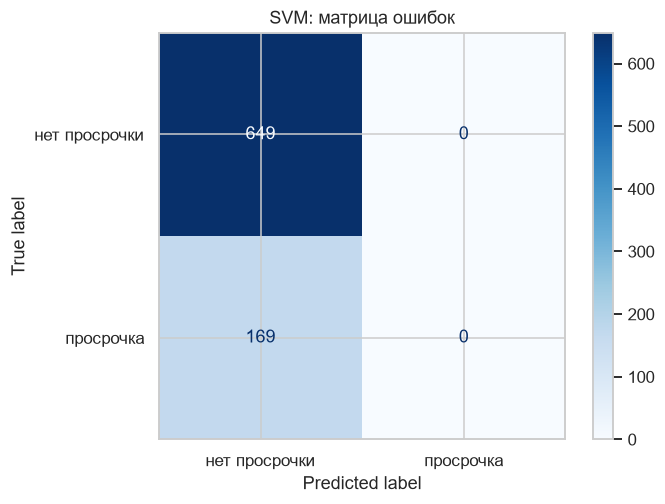

Accuracy:  0.793
Precision: 0.000
Recall:    0.000
F1:        0.000
ROC-AUC:   0.444
Помечено как 1: 0


In [4]:
svm_grid = GridSearchCV(
    SVC(random_state=42),
    param_grid={"C": [0.1, 1, 10], "kernel": ["linear", "rbf"]},
    cv=3,
    scoring="roc_auc",
)
svm_grid.fit(X_train_s, y_train)

print("Лучшие параметры:", svm_grid.best_params_)
print(f"ROC-AUC на кросс-валидации: {svm_grid.best_score_:.3f}")

svm = svm_grid.best_estimator_
y_pred_svm = svm.predict(X_test_s)
y_score_svm = svm.decision_function(X_test_s)

cm = confusion_matrix(y_test, y_pred_svm)
ConfusionMatrixDisplay(cm, display_labels=["нет просрочки", "просрочка"]).plot(cmap="Blues")
plt.title("SVM: матрица ошибок")
plt.show()

show_metrics(y_test, y_pred_svm, y_score_svm)

In [5]:
svm_cv = pd.DataFrame(svm_grid.cv_results_)[
    ["param_C", "param_kernel", "mean_test_score", "std_test_score"]
]
svm_cv.columns = ["C", "ядро", "ROC-AUC (CV)", "std по фолдам"]
print(svm_cv.to_string(index=False))

     C   ядро  ROC-AUC (CV)  std по фолдам
 0.100 linear         0.515          0.015
 0.100    rbf         0.527          0.020
 1.000 linear         0.482          0.028
 1.000    rbf         0.518          0.017
10.000 linear         0.530          0.034
10.000    rbf         0.513          0.023


## 4. Разделяющая линия SVM

Границу можно нарисовать только в двух измерениях. Для картинки берём два признака — доход и возраст — и учим отдельный линейный SVM на них. Это иллюстрация формы границы, а не модель из раздела 3: та (linear, `C=10`, без весов классов) никого не относит к просрочке, а здесь `C=1` и веса классов. Рисуем обучающие точки: опорные векторы тоже из обучающей выборки.

Классы несбалансированы (около 21% единиц) и линейно не разделимы, поэтому обычный SVM с `C=1` вырождается: веса почти нулевые, решающая функция везде около −1, и линия ничего не значит. Чтобы получить осмысленную границу, задаём `class_weight="balanced"`: ошибка на редком классе штрафуется сильнее. Сплошная линия — граница, пунктирные — края зазора, кружки — опорные векторы.

Без весов классов: max |w| = 0.000011
Граница: -0.574·доход -0.023·возраст +0.294 = 0 (признаки стандартизованы)
Опорных векторов: 1575 из 1659


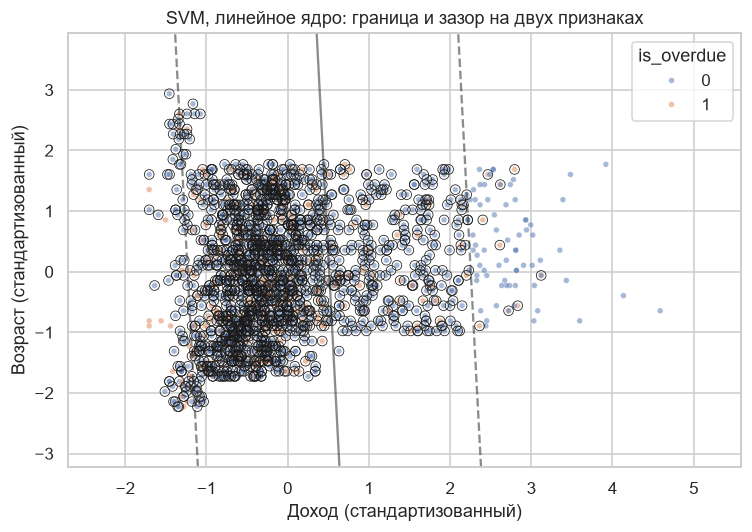

In [6]:
plot_cols = ["annual_income", "customer_age"]
scaler_2d = StandardScaler()
X_train_2d = scaler_2d.fit_transform(X_train[plot_cols])

# обычный SVM: веса почти нулевые, границы нет
svm_plain = SVC(kernel="linear", C=1, random_state=42).fit(X_train_2d, y_train)
print(f"Без весов классов: max |w| = {np.abs(svm_plain.coef_).max():.6f}")

# SVM с весами классов: осмысленная граница
svm_2d = SVC(kernel="linear", C=1, class_weight="balanced", random_state=42).fit(X_train_2d, y_train)
w1, w2 = svm_2d.coef_[0]
b = svm_2d.intercept_[0]
print(f"Граница: {w1:.3f}·доход {w2:+.3f}·возраст {b:+.3f} = 0 (признаки стандартизованы)")
print(f"Опорных векторов: {len(svm_2d.support_vectors_)} из {len(X_train_2d)}")

fig, ax = plt.subplots(figsize=(7, 5))
DecisionBoundaryDisplay.from_estimator(
    svm_2d,
    X_train_2d,
    plot_method="contour",
    colors="k",
    levels=[-1, 0, 1],
    alpha=0.5,
    linestyles=["--", "-", "--"],
    ax=ax,
)
sns.scatterplot(
    x=X_train_2d[:, 0], y=X_train_2d[:, 1], hue=y_train,
    palette={0: "C0", 1: "C1"}, s=14, alpha=0.5, ax=ax,
)
ax.scatter(
    svm_2d.support_vectors_[:, 0], svm_2d.support_vectors_[:, 1],
    s=40, linewidth=0.5, facecolors="none", edgecolors="k",
)
ax.set_xlabel("Доход (стандартизованный)")
ax.set_ylabel("Возраст (стандартизованный)")
ax.set_title("SVM, линейное ядро: граница и зазор на двух признаках")
plt.tight_layout()
plt.show()

## 5. Дерево решений

Перебираем глубину и минимальный размер листа. Это те же ограничения против переобучения, что на лекции: `max_depth` и `min_samples_leaf`. Критерий подбора снова ROC-AUC.

Критерий качества разбиения в `sklearn` по умолчанию — индекс Джини; на лекции разбирали энтропию и прирост информации, идея та же: выбрать правило, после которого классы в подвыборках чище.

Лучшие параметры: {'max_depth': 2, 'min_samples_leaf': 100}
ROC-AUC на кросс-валидации: 0.543


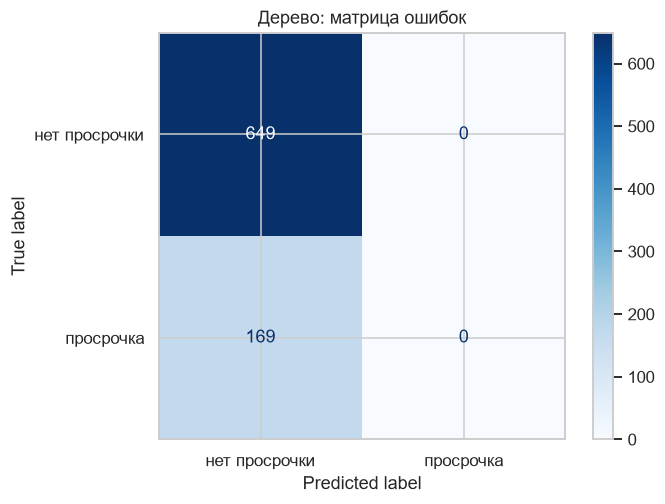

Accuracy:  0.793
Precision: 0.000
Recall:    0.000
F1:        0.000
ROC-AUC:   0.562
Помечено как 1: 0


In [7]:
tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": [2, 3, 5, None], "min_samples_leaf": [10, 50, 100]},
    cv=3,
    scoring="roc_auc",
)
tree_grid.fit(X_train, y_train)

print("Лучшие параметры:", tree_grid.best_params_)
print(f"ROC-AUC на кросс-валидации: {tree_grid.best_score_:.3f}")

tree = tree_grid.best_estimator_
y_pred_tree = tree.predict(X_test)
y_score_tree = tree.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred_tree)
ConfusionMatrixDisplay(cm, display_labels=["нет просрочки", "просрочка"]).plot(cmap="Blues")
plt.title("Дерево: матрица ошибок")
plt.show()

show_metrics(y_test, y_pred_tree, y_score_tree)

In [8]:
tree_cv = pd.DataFrame(tree_grid.cv_results_)[
    ["param_max_depth", "param_min_samples_leaf", "mean_test_score", "std_test_score"]
]
tree_cv.columns = ["max_depth", "min_samples_leaf", "ROC-AUC (CV)", "std по фолдам"]
print(tree_cv.sort_values("ROC-AUC (CV)", ascending=False).to_string(index=False))

max_depth  min_samples_leaf  ROC-AUC (CV)  std по фолдам
        2               100         0.543          0.030
        2                50         0.538          0.034
        3               100         0.536          0.020
        3                10         0.530          0.032
        2                10         0.528          0.020
        5               100         0.526          0.013
     None               100         0.523          0.013
        3                50         0.521          0.035
     None                50         0.513          0.028
        5                50         0.512          0.031
        5                10         0.504          0.016
     None                10         0.500          0.016


## 6. Визуализация дерева и разделяющих прямых

Сначала дерево из раздела 5 на всех семи признаках. Затем — отдельное дерево на двух признаках (доход и возраст), чтобы нарисовать его разделяющие прямые на плоскости. Деревьям масштаб не нужен, поэтому оси в исходных единицах. Это отдельная модель: при низком доходе она делит по возрасту (около 32 лет), а дерево из раздела 5 — по статусу занятости 2. Выводы ниже описывают дерево из раздела 5.

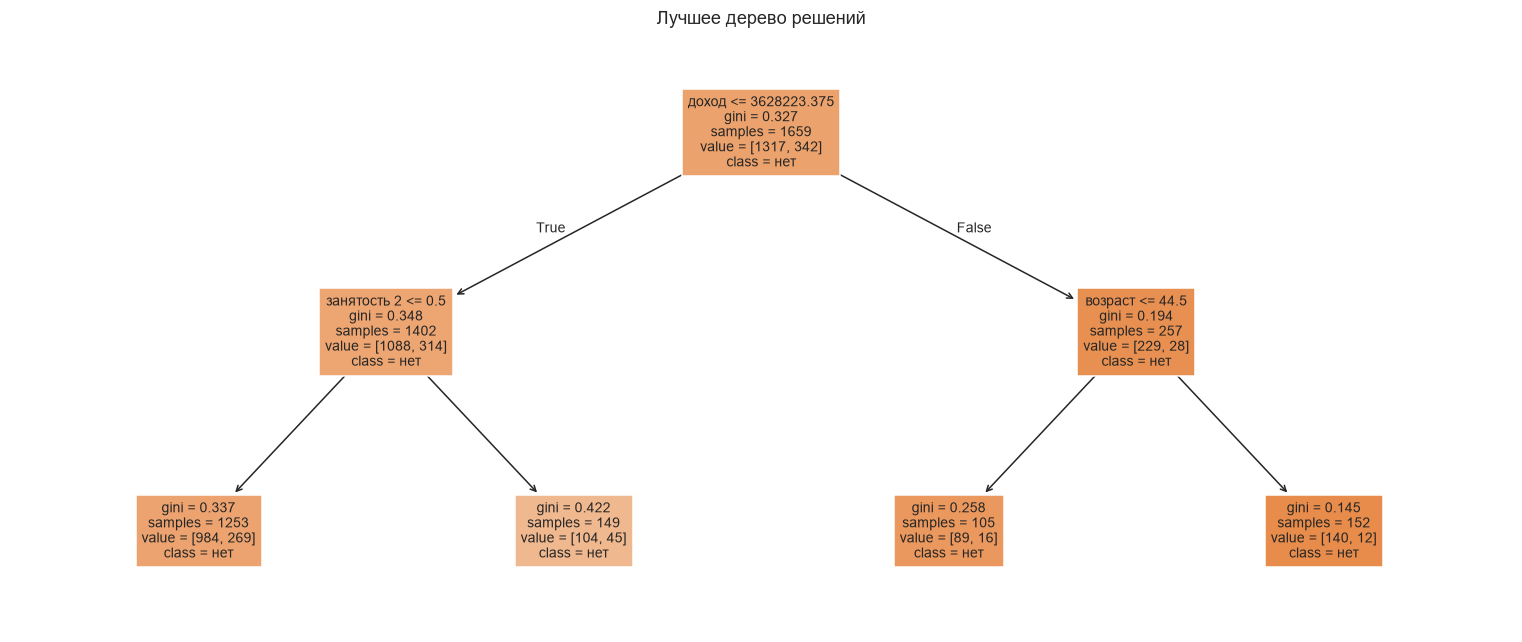

annual_income      0.680
emp_2              0.240
customer_age       0.079
interest_rate      0.000
term_months        0.000
principal_amount   0.000
product_2          0.000


In [9]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(
    tree, filled=True, fontsize=9,
    feature_names=["доход", "возраст", "ставка", "срок", "сумма", "продукт 2", "занятость 2"],
    class_names=["нет", "просрочка"],
    ax=ax,
)
plt.title("Лучшее дерево решений")
plt.tight_layout()
plt.show()

imp = pd.Series(tree.feature_importances_, index=features_col).sort_values(ascending=False)
print(imp.round(3).to_string())

|--- доход <= 3628223.38
|   |--- возраст <= 32.50
|   |   |--- weights: [224.00, 52.00] class: 0
|   |--- возраст >  32.50
|   |   |--- weights: [864.00, 262.00] class: 0
|--- доход >  3628223.38
|   |--- возраст <= 44.50
|   |   |--- weights: [89.00, 16.00] class: 0
|   |--- возраст >  44.50
|   |   |--- weights: [140.00, 12.00] class: 0



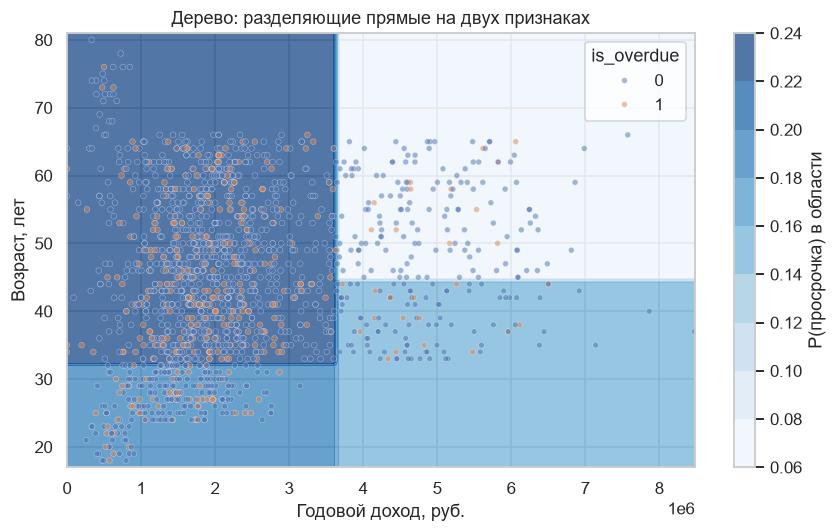

In [10]:
from sklearn.tree import export_text

tree_2d = DecisionTreeClassifier(max_depth=2, min_samples_leaf=100, random_state=42)
tree_2d.fit(X_train[plot_cols].values, y_train)
print(export_text(tree_2d, feature_names=["доход", "возраст"], show_weights=True))

fig, ax = plt.subplots(figsize=(8, 5))
disp = DecisionBoundaryDisplay.from_estimator(
    tree_2d, X_train[plot_cols].values, response_method="predict_proba",
    cmap="Blues", alpha=0.7, ax=ax,
)
fig.colorbar(disp.surface_, ax=ax, label="P(просрочка) в области")
sns.scatterplot(
    x=X_train["annual_income"], y=X_train["customer_age"], hue=y_train,
    palette={0: "C0", 1: "C1"}, s=14, alpha=0.5, ax=ax,
)
ax.set_xlabel("Годовой доход, руб.")
ax.set_ylabel("Возраст, лет")
ax.set_title("Дерево: разделяющие прямые на двух признаках")
plt.tight_layout()
plt.show()

## 7. Выводы

**Качество.**  
Обе модели слабые и близки к случайному угадыванию, как в логистической регрессии и KNN: признаки на момент выдачи плохо отделяют просрочку.  
SVM: ROC-AUC на кросс-валидации у всех шести комбинаций параметров примерно 0.48–0.53; разница между ними (до 0.05) того же порядка, что разброс по фолдам (std около 0.02, таблица выше). На тесте ROC-AUC около 0.5, в пределах разброса кросс-валидации (в разных запусках встречались значения от 0.44 до 0.53) — это уровень шума, а не сигнал.  
Дерево: ROC-AUC на кросс-валидации около 0.54, на тесте около 0.56. Чуть выше SVM, но тоже слабо.

**Матрица ошибок.**  
Обе модели ни одному кредиту не ставят класс 1. У дерева вероятность просрочки во всех листьях ниже 0.5 (максимум около 30%). У SVM решающая функция отрицательна для всех объектов. Поэтому precision, recall и F1 равны нулю, а accuracy (около 0.79) совпадает с правилом «всем 0». Это не ошибка кода, а следствие дисбаланса и слабого сигнала. Сравнивать модели по accuracy здесь нельзя, поэтому смотрим ROC-AUC.

**Зависимости (дерево).**  
Дерево глубины 2 использует три правила: доход около 3.6 млн рублей, затем для низкого дохода — статус занятости 2, для высокого — возраст около 45 лет. Доля просрочек в листьях на обучающей выборке:  
— доход ниже 3.6 млн, статус 2: около 30%;  
— доход ниже 3.6 млн, другой статус: около 21%;  
— доход выше 3.6 млн, моложе 45: около 15%;  
— доход выше 3.6 млн, старше 45: около 8%.  
Важность признаков: доход 0.68, статус 2 около 0.24, возраст около 0.08; ставка, срок, сумма и продукт не использованы. Это согласуется с логистической регрессией: выше доход — ниже риск, статус 2 — выше. Возраст там был незначим. В дереве он работает только внутри группы с высоким доходом, а она небольшая (257 кредитов, 28 просрочек), поэтому разницу 15% и 8% надёжной считать нельзя.

**Зависимости (SVM).**  
Нелинейное ядро ничего не добавило: лучший вариант (linear, C=10) почти не отличается от rbf, так что выбор ядра здесь формальный. На двух признаках обычный линейный SVM вырождается (веса почти нулевые). С весами классов граница почти вертикальна по доходу: ниже доход — к классу 1, то есть то же направление связи. Почти все точки при этом оказываются опорными, зазор чистым не получается.

**Практический смысл.**  
Разделяющей границы, которая чисто отделяет просроченные кредиты, в этих признаках нет. Дерево интерпретируемее: даёт читаемые правила и находит те же слабые закономерности, что и логистическая регрессия. Но как скоринговая карта обе модели слабые.